In [1]:
import sys
import natcap.invest
from natcap.invest import seasonal_water_yield

print("Python:", sys.executable)
print("InVEST version:", natcap.invest.__version__)
print("SWY ready")

Python: D:\All Softwares\Anaconda\envs\invest-swy\python.exe
InVEST version: 3.20.2
SWY ready


In [2]:
from natcap.invest import seasonal_water_yield

for item in seasonal_water_yield.MODEL_SPEC.inputs:
    if item.id in [
        "precip_raster_table",
        "et0_raster_table",
        "rain_events_table_path"
    ]:
        print("\nINPUT:", item.id)
        print(item)


INPUT: et0_raster_table
id='et0_raster_table' about='Table mapping month indexes (1-12) to reference evapotranspiration raster paths. The paths may be either absolute or relative to the location of the ET0 table itself. There must be one reference evapotranspiration raster provided for each of the 12 months. Required if User-Defined Local Recharge is not selected.' name='ET0 table' required='not user_defined_local_recharge' allowed='not user_defined_local_recharge' hidden=False permissions='r' columns=[IntegerInput(id='month', about='The month index (1-12).', name=None, required=True, allowed=True, hidden=False, units=None, expression='(value >= 1) & (value <= 12)'), SingleBandRasterInput(id='path', about='Path to a reference evapotranspiration raster for the month.', name=None, required=True, allowed=True, hidden=False, permissions='r', projected=None, projection_units=None, data_type=<class 'float'>, units=<Unit('millimeter / month')>)] orientation='column' index_col=None na_allowed

In [4]:

from pathlib import Path

# Replace these if your 1995 folder names differ
PRECIP_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\Precipitation_final"
)

ET0_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\FINAL_EVAPOTRANSPIRATION"
)

print("1995 PRECIPITATION FILES:")
if PRECIP_1995.exists():
    for f in sorted(PRECIP_1995.glob("*.tif")):
        print(f.name)
else:
    print("Folder not found:", PRECIP_1995)

print("\n1995 ET0 FILES:")
if ET0_1995.exists():
    for f in sorted(ET0_1995.glob("*.tif")):
        print(f.name)
else:
    print("Folder not found:", ET0_1995)


1995 PRECIPITATION FILES:
1.tif
10.tif
11.tif
12.tif
2.tif
3.tif
4.tif
5.tif
6.tif
7.tif
8.tif
9.tif

1995 ET0 FILES:
1.tif
10.tif
11.tif
12.tif
2.tif
3.tif
4.tif
5.tif
6.tif
7.tif
8.tif
9.tif


In [5]:
from pathlib import Path

# 1995 precipitation
PRECIP_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\Precipitation_final"
)

# 1995 ET0 (stored in a folder named 2015)
ET0_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\FINAL_EVAPOTRANSPIRATION"
)

# 1985 LULC
LULC_1985 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1985\LULC\Fiinal_LULC_1985.tif"
)

In [11]:

import csv
from pathlib import Path

PRECIP_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\Precipitation_final"
)

ET0_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\FINAL_EVAPOTRANSPIRATION"
)

OUTPUT = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C1"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

def make_table(folder, filename):
    csv_path = OUTPUT / filename

    with open(csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["month", "path"])

        for month in range(1, 13):
            raster = folder / f"{month}.tif"
            if not raster.is_file():
                raise FileNotFoundError(raster)
            writer.writerow([month, str(raster)])

    return str(csv_path)

precip_csv = make_table(PRECIP_1995, "precip_C1.csv")
et0_csv = make_table(ET0_1995, "et0_C1.csv")

print("Precipitation:", precip_csv)
print("ET0:", et0_csv)
print("Monthly tables created successfully.")

Precipitation: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C1\precip_C1.csv
ET0: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C1\et0_C1.csv
Monthly tables created successfully.


In [12]:

from natcap.invest import seasonal_water_yield

args = {
    "workspace_dir": str(OUTPUT),
    "results_suffix": "C1",

    "dem_raster_path": r"E:\MYLSU\1.2_Seasonal_Water_Yield\DEM\111111Final_DEM.tif",

    "lulc_raster_path": r"E:\MYLSU\1.2_Seasonal_Water_Yield\1985\LULC\Fiinal_LULC_1985.tif",

    "soil_group_path": r"E:\MYLSU\1.2_Seasonal_Water_Yield\Soil_Hydrology\Final_soil_hydfology.tif",

    "aoi_path": r"E:\MYLSU\1.2_Seasonal_Water_Yield\AOI\final_watershed_area11122.shp",

    "biophysical_table_path": r"E:\MYLSU\1.2_Seasonal_Water_Yield\1985\Biophysical_Table.csv",

    "precip_raster_table": precip_csv,
    "et0_raster_table": et0_csv,

    "rain_events_table_path": r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\Rain_Events_Table.csv",

    "threshold_flow_accumulation": 1000,
    "alpha_m": 1/12,
    "beta_i": 1,
    "gamma": 1,

    "user_defined_local_recharge": False,
    "user_defined_climate_zones": False,
    "monthly_alpha": False,
    "flow_dir_algorithm": "D8"
}

warnings = seasonal_water_yield.validate(args)

if warnings:
    print("Validation warnings:")
    for warning in warnings:
        print(warning)
else:
    print("All C1 inputs validated successfully!")


All C1 inputs validated successfully!


In [13]:
seasonal_water_yield.execute(args)
print("C1 simulation completed successfully!")

C1 simulation completed successfully!


In [9]:

import geopandas as gpd
from pathlib import Path

OUTPUT = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C1"
)

results = gpd.read_file(
    OUTPUT / "aggregated_results_swy_C1.shp"
)

print("Available columns:")
print(results.columns.tolist())

print("\nC1 watershed results:")
print(results.to_string(index=False))


Available columns:
['HUC8', 'NAME', 'Shape__Are', 'Shape__Len', 'Field', 'Field1', 'qb', 'vri_sum', 'geom_id', 'geometry']

C1 watershed results:
    HUC8                  NAME  Shape__Are    Shape__Len        Field      Field1        qb  vri_sum  geom_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

In [14]:

import csv
from pathlib import Path
from natcap.invest import seasonal_water_yield

# =====================================
# C2 = 2005 CLIMATE + 1995 LULC
# =====================================

# 2005 monthly precipitation folder
PRECIP_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2005\FINAL_PRECIPITATION"
)

# 2005 monthly ET0 folder
ET0_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\FINAL_EVAPOTRANSPIRATION"
)

# 2005 rain-events CSV
RAIN_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2005\Rain_Events_Table.csv"
)

# 1995 LULC raster
LULC_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\LULC_1995\Final_LULC_1995.tif"
)

# C2 output workspace
OUTPUT_C2 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C2"
)

# Fixed inputs from your original SWY model
DEM = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\DEM\111111Final_DEM.tif"
)

SOIL = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Soil_Hydrology\Final_soil_hydfology.tif"
)

WATERSHED = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\AOI\final_watershed_area11122.shp"
)

BIOPHYSICAL = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\Biophysical_Table.csv"
)

# Verify required files and folders
inputs_to_check = {
    "2005 precipitation folder": PRECIP_2005,
    "2005 ET0 folder": ET0_2005,
    "2005 rain-events CSV": RAIN_2005,
    "1995 LULC raster": LULC_1995,
    "DEM": DEM,
    "Soil": SOIL,
    "Watershed": WATERSHED,
    "Biophysical table": BIOPHYSICAL,
}

missing = []

for name, path in inputs_to_check.items():
    if not path.exists():
        missing.append(f"{name}: {path}")
    else:
        print(f"Found: {name}")

if missing:
    raise FileNotFoundError(
        "Correct these input paths before continuing:\n"
        + "\n".join(missing)
    )

OUTPUT_C2.mkdir(parents=True, exist_ok=True)
print("All C2 paths verified!")


Found: 2005 precipitation folder
Found: 2005 ET0 folder
Found: 2005 rain-events CSV
Found: 1995 LULC raster
Found: DEM
Found: Soil
Found: Watershed
Found: Biophysical table
All C2 paths verified!


In [15]:
def make_table_C2(folder, filename):
    csv_path = OUTPUT_C2 / filename

    with open(csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["month", "path"])

        for month in range(1, 13):
            raster = folder / f"{month}.tif"

            if not raster.is_file():
                raise FileNotFoundError(raster)

            writer.writerow([month, str(raster)])

    return str(csv_path)


precip_C2 = make_table_C2(
    PRECIP_2005, "precip_C2.csv"
)

et0_C2 = make_table_C2(
    ET0_2005, "et0_C2.csv"
)

print("Precipitation:", precip_C2)
print("ET0:", et0_C2)
print("C2 monthly tables created successfully!")

Precipitation: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C2\precip_C2.csv
ET0: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C2\et0_C2.csv
C2 monthly tables created successfully!


In [16]:
args_C2 = {
    "workspace_dir": str(OUTPUT_C2),
    "results_suffix": "C2",

    "dem_raster_path": str(DEM),
    "lulc_raster_path": str(LULC_1995),
    "soil_group_path": str(SOIL),
    "aoi_path": str(WATERSHED),
    "biophysical_table_path": str(BIOPHYSICAL),

    "precip_raster_table": precip_C2,
    "et0_raster_table": et0_C2,
    "rain_events_table_path": str(RAIN_2005),

    "threshold_flow_accumulation": 1000,
    "alpha_m": 1/12,
    "beta_i": 1,
    "gamma": 1,

    "user_defined_local_recharge": False,
    "user_defined_climate_zones": False,
    "monthly_alpha": False,
    "flow_dir_algorithm": "D8"
}

warnings = seasonal_water_yield.validate(args_C2)

if warnings:
    print("Validation warnings:")
    for warning in warnings:
        print(warning)
else:
    print("All C2 inputs validated successfully!")

All C2 inputs validated successfully!


In [17]:
if not warnings:
    seasonal_water_yield.execute(args_C2)
    print("C2 simulation completed successfully!")
else:
    print("Resolve validation warnings before running C2.")

C2 simulation completed successfully!


In [18]:

import csv
from pathlib import Path
from natcap.invest import seasonal_water_yield

# =====================================
# C3 = 2015 CLIMATE + 2005 LULC
# =====================================

# 2015 monthly precipitation
PRECIP_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\FINAL_PRECIPITATION"
)

# 2015 monthly ET0
ET0_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\FINAL_EVAPOTRANSPIRATION"
)

# 2015 rain-events table
RAIN_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\Rain_Events_Table.csv"
)

# 2005 LULC
LULC_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2005\LULC\LULC_Final_2005.tif"
)

# 2005 biophysical table
BIOPHYSICAL_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\Biophysical_Table.csv"
)

# C3 output folder
OUTPUT_C3 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C3"
)

# Fixed inputs, same as previous scenarios
DEM = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\DEM\111111Final_DEM.tif"
)

SOIL = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Soil_Hydrology\Final_soil_hydfology.tif"
)

WATERSHED = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\AOI\final_watershed_area11122.shp"
)

# Verify paths
inputs_to_check_C3 = {
    "2015 precipitation": PRECIP_2015,
    "2015 ET0": ET0_2015,
    "2015 rain events": RAIN_2015,
    "2005 LULC": LULC_2005,
    "2005 biophysical table": BIOPHYSICAL_2005,
    "DEM": DEM,
    "Soil": SOIL,
    "Watershed": WATERSHED,
}

missing_C3 = []

for name, path in inputs_to_check_C3.items():
    if not path.exists():
        missing_C3.append(f"{name}: {path}")
    else:
        print(f"Found: {name}")

if missing_C3:
    raise FileNotFoundError(
        "Correct these C3 paths:\n" +
        "\n".join(missing_C3)
    )

OUTPUT_C3.mkdir(parents=True, exist_ok=True)
print("All C3 paths verified!")


Found: 2015 precipitation
Found: 2015 ET0
Found: 2015 rain events
Found: 2005 LULC
Found: 2005 biophysical table
Found: DEM
Found: Soil
Found: Watershed
All C3 paths verified!


In [19]:
def make_table_C3(folder, filename):
    csv_path = OUTPUT_C3 / filename

    with open(csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["month", "path"])

        for month in range(1, 13):
            raster = folder / f"{month}.tif"

            if not raster.is_file():
                raise FileNotFoundError(raster)

            writer.writerow([month, str(raster)])

    return str(csv_path)

precip_C3 = make_table_C3(PRECIP_2015, "precip_C3.csv")
et0_C3 = make_table_C3(ET0_2015, "et0_C3.csv")

print("C3 monthly tables created successfully!")

C3 monthly tables created successfully!


In [20]:
args_C3 = {
    "workspace_dir": str(OUTPUT_C3),
    "results_suffix": "C3",

    "dem_raster_path": str(DEM),
    "lulc_raster_path": str(LULC_2005),
    "soil_group_path": str(SOIL),
    "aoi_path": str(WATERSHED),
    "biophysical_table_path": str(BIOPHYSICAL_2005),

    "precip_raster_table": precip_C3,
    "et0_raster_table": et0_C3,
    "rain_events_table_path": str(RAIN_2015),

    "threshold_flow_accumulation": 1000,
    "alpha_m": 1/12,
    "beta_i": 1,
    "gamma": 1,

    "user_defined_local_recharge": False,
    "user_defined_climate_zones": False,
    "monthly_alpha": False,
    "flow_dir_algorithm": "D8"
}

warnings_C3 = seasonal_water_yield.validate(args_C3)

if warnings_C3:
    print("Validation warnings:")
    for warning in warnings_C3:
        print(warning)
else:
    print("All C3 inputs validated successfully!")

All C3 inputs validated successfully!


In [21]:
print("Starting C3 simulation...")

seasonal_water_yield.execute(args_C3)

print("C3 simulation completed successfully!")
print("Results saved in:", OUTPUT_C3)

Starting C3 simulation...
C3 simulation completed successfully!
Results saved in: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C3


In [32]:

import csv
from pathlib import Path
from natcap.invest import seasonal_water_yield

# =====================================
# C4 = 2023 CLIMATE + 2015 LULC
# =====================================

# 2023 monthly precipitation
PRECIP_2023 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\FINAL_PRECIPITATION"
)

# 2023 monthly ET0
ET0_2023 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Final_evapotranspiration_2023"
)

# 2023 rain-events table
RAIN_2023 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Rainfall_Event_Latest.csv"
)

# 2015 LULC
LULC_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\LULC\Final_LULC.tif"
)

# 2015 biophysical table
BIOPHYSICAL_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\Biophysical_Table.csv"
)

# C4 output folder
OUTPUT_C4 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4"
)

# Fixed inputs
DEM = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\DEM\111111Final_DEM.tif"
)

SOIL = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Soil_Hydrology\Final_soil_hydfology.tif"
)

WATERSHED = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\AOI\final_watershed_area11122.shp"
)

# Verify paths
inputs_to_check_C4 = {
    "2023 precipitation": PRECIP_2023,
    "2023 ET0": ET0_2023,
    "2023 rain events": RAIN_2023,
    "2015 LULC": LULC_2015,
    "2015 biophysical table": BIOPHYSICAL_2015,
    "DEM": DEM,
    "Soil": SOIL,
    "Watershed": WATERSHED,
}

missing_C4 = []

for name, path in inputs_to_check_C4.items():
    if not path.exists():
        missing_C4.append(f"{name}: {path}")
    else:
        print(f"Found: {name}")

if missing_C4:
    raise FileNotFoundError(
        "Correct these C4 paths:\n" +
        "\n".join(missing_C4)
    )

OUTPUT_C4.mkdir(parents=True, exist_ok=True)
print("All C4 paths verified!")


Found: 2023 precipitation
Found: 2023 ET0
Found: 2023 rain events
Found: 2015 LULC
Found: 2015 biophysical table
Found: DEM
Found: Soil
Found: Watershed
All C4 paths verified!


In [34]:
print("Precipitation folder:", PRECIP_2023)

print("\nFiles inside precipitation folder:")
for file in sorted(PRECIP_2023.iterdir()):
    print(file.name)

Precipitation folder: E:\MYLSU\1.2_Seasonal_Water_Yield\FINAL_PRECIPITATION

Files inside precipitation folder:
P1.tif
P10.tif
P11.tif
P12.tif
P2.tif
P3.tif
P4.tif
P5.tif
P6.tif
P7.tif
P8.tif
P9.tif


In [35]:
precip_C4 = OUTPUT_C4 / "precip_C4.csv"

with open(precip_C4, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["month", "path"])

    for month in range(1, 13):
        raster = PRECIP_2023 / f"P{month}.tif"

        if not raster.is_file():
            raise FileNotFoundError(raster)

        writer.writerow([month, str(raster)])

precip_C4 = str(precip_C4)

print("2023 precipitation table created successfully!")
print(precip_C4)

2023 precipitation table created successfully!
E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4\precip_C4.csv


In [36]:
print("ET0 folder:", ET0_2023)

for file in sorted(ET0_2023.iterdir()):
    print(file.name)

ET0 folder: E:\MYLSU\1.2_Seasonal_Water_Yield\Final_evapotranspiration_2023
1.tif
10.tif
11.tif
12.tif
2.tif
3.tif
4.tif
5.tif
6.tif
7.tif
8.tif
9.tif


In [37]:
et0_C4 = OUTPUT_C4 / "et0_C4.csv"

with open(et0_C4, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["month", "path"])

    for month in range(1, 13):
        raster = ET0_2023 / f"{month}.tif"

        if not raster.is_file():
            raise FileNotFoundError(raster)

        writer.writerow([month, str(raster)])

et0_C4 = str(et0_C4)

print("2023 ET0 table created successfully!")
print(et0_C4)

2023 ET0 table created successfully!
E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4\et0_C4.csv


In [38]:
args_C4 = {
    "workspace_dir": str(OUTPUT_C4),
    "results_suffix": "C4",

    "dem_raster_path": str(DEM),
    "lulc_raster_path": str(LULC_2015),
    "soil_group_path": str(SOIL),
    "aoi_path": str(WATERSHED),
    "biophysical_table_path": str(BIOPHYSICAL_2015),

    "precip_raster_table": precip_C4,
    "et0_raster_table": et0_C4,
    "rain_events_table_path": str(RAIN_2023),

    "threshold_flow_accumulation": 1000,
    "alpha_m": 1/12,
    "beta_i": 1,
    "gamma": 1,

    "user_defined_local_recharge": False,
    "user_defined_climate_zones": False,
    "monthly_alpha": False,
    "flow_dir_algorithm": "D8"
}

warnings_C4 = seasonal_water_yield.validate(args_C4)

if warnings_C4:
    print("Validation warnings:")
    for warning in warnings_C4:
        print(warning)
else:
    print("All C4 inputs validated successfully!")

Validation warnings:
(['rain_events_table_path'], 'Expected the column "events" but did not find it')


In [39]:

import pandas as pd

# Read original 2023 rain-events table
rain_df = pd.read_csv(RAIN_2023)

print("Original rain-events table:")
print(rain_df)

# Convert month names to numbers
month_map = {
    "jan": 1, "january": 1,
    "feb": 2, "february": 2,
    "mar": 3, "march": 3,
    "apr": 4, "april": 4,
    "may": 5,
    "jun": 6, "june": 6,
    "jul": 7, "july": 7,
    "aug": 8, "august": 8,
    "sep": 9, "sept": 9, "september": 9,
    "oct": 10, "october": 10,
    "nov": 11, "november": 11,
    "dec": 12, "december": 12
}

rain_df["month"] = (
    rain_df["month"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(month_map)
)

# Check that all months were converted
if rain_df["month"].isna().any():
    raise ValueError(
        "Some month names could not be converted."
    )

# Verify exactly 12 unique months
if sorted(rain_df["month"].astype(int).tolist()) != list(range(1, 13)):
    raise ValueError(
        "Rain-events table must contain each month from 1 to 12 exactly once."
    )

rain_df["month"] = rain_df["month"].astype(int)
rain_df = rain_df.sort_values("month")

# Save corrected copy in C4 folder
RAIN_2023_FIXED = OUTPUT_C4 / "rain_events_2023_fixed.csv"

rain_df.to_csv(RAIN_2023_FIXED, index=False)

print("\nCorrected rain-events table:")
print(rain_df)
print("\nSaved to:", RAIN_2023_FIXED)


Original rain-events table:
    Month  2023
0       1     2
1       2     5
2       3     2
3       4     5
4       5    13
5       6     6
6       7     6
7       8     2
8       9     5
9      10     5
10     11     4
11     12     4


KeyError: 'month'

In [40]:
import pandas as pd

# Read original 2023 rain-events CSV
rain_df = pd.read_csv(RAIN_2023)

# Correct column names
rain_df.columns = ["month", "events"]

# Verify months
assert sorted(rain_df["month"].tolist()) == list(range(1, 13))

# Save corrected copy
RAIN_2023_FIXED = OUTPUT_C4 / "rain_events_2023_fixed.csv"

rain_df.to_csv(RAIN_2023_FIXED, index=False)

print("Corrected rain-events table:")
print(rain_df.to_string(index=False))

print("\nSaved successfully:", RAIN_2023_FIXED)

Corrected rain-events table:
 month  events
     1       2
     2       5
     3       2
     4       5
     5      13
     6       6
     7       6
     8       2
     9       5
    10       5
    11       4
    12       4

Saved successfully: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4\rain_events_2023_fixed.csv


In [41]:
args_C4["rain_events_table_path"] = str(RAIN_2023_FIXED)

warnings_C4 = seasonal_water_yield.validate(args_C4)

if warnings_C4:
    print("Validation warnings:")
    for warning in warnings_C4:
        print(warning)
else:
    print("All C4 inputs validated successfully!")

All C4 inputs validated successfully!


In [42]:
if not warnings_C4:
    print("Starting C4 simulation...")

    seasonal_water_yield.execute(args_C4)

    print("C4 simulation completed successfully!")
else:
    print("Resolve validation warnings first.")

Starting C4 simulation...
C4 simulation completed successfully!


In [43]:

from pathlib import Path
from natcap.invest import seasonal_water_yield

# =====================================
# C5 = 2023 CLIMATE + 1985 LULC
# =====================================

# C5 output folder
OUTPUT_C5 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C5"
)

OUTPUT_C5.mkdir(parents=True, exist_ok=True)

# 1985 LULC
LULC_1985 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1985\LULC\Fiinal_LULC_1985.tif"
)

# 1985 biophysical table
BIOPHYSICAL_1985 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1985\Biophysical_Table.csv"
)

# Reuse the successful C4 climate input tables
PRECIP_C5 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4\precip_C4.csv"
)

ET0_C5 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4\et0_C4.csv"
)

RAIN_C5 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C4\rain_events_2023_fixed.csv"
)

# Fixed inputs from previous simulations
DEM = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\DEM\111111Final_DEM.tif"
)

SOIL = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Soil_Hydrology\Final_soil_hydfology.tif"
)

WATERSHED = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\AOI\final_watershed_area11122.shp"
)

# Verify all input paths
inputs_C5 = {
    "1985 LULC": LULC_1985,
    "1985 biophysical table": BIOPHYSICAL_1985,
    "2023 precipitation table": PRECIP_C5,
    "2023 ET0 table": ET0_C5,
    "2023 rain-events table": RAIN_C5,
    "DEM": DEM,
    "Soil": SOIL,
    "Watershed": WATERSHED,
}

missing_C5 = []

for name, path in inputs_C5.items():
    if not path.is_file():
        missing_C5.append(f"{name}: {path}")
    else:
        print(f"Found: {name}")

if missing_C5:
    raise FileNotFoundError(
        "Correct these C5 input paths:\n"
        + "\n".join(missing_C5)
    )

print("All C5 paths verified!")


Found: 1985 LULC
Found: 1985 biophysical table
Found: 2023 precipitation table
Found: 2023 ET0 table
Found: 2023 rain-events table
Found: DEM
Found: Soil
Found: Watershed
All C5 paths verified!


In [44]:
args_C5 = {
    "workspace_dir": str(OUTPUT_C5),
    "results_suffix": "C5",

    "dem_raster_path": str(DEM),
    "lulc_raster_path": str(LULC_1985),
    "soil_group_path": str(SOIL),
    "aoi_path": str(WATERSHED),
    "biophysical_table_path": str(BIOPHYSICAL_1985),

    "precip_raster_table": str(PRECIP_C5),
    "et0_raster_table": str(ET0_C5),
    "rain_events_table_path": str(RAIN_C5),

    "threshold_flow_accumulation": 1000,
    "alpha_m": 1/12,
    "beta_i": 1,
    "gamma": 1,

    "user_defined_local_recharge": False,
    "user_defined_climate_zones": False,
    "monthly_alpha": False,
    "flow_dir_algorithm": "D8"
}

warnings_C5 = seasonal_water_yield.validate(args_C5)

if warnings_C5:
    print("Validation warnings:")
    for warning in warnings_C5:
        print(warning)
else:
    print("All C5 inputs validated successfully!")

All C5 inputs validated successfully!


In [45]:
if not warnings_C5:
    print("Starting C5 simulation...")

    seasonal_water_yield.execute(args_C5)

    print("C5 simulation completed successfully!")
    print("Results saved in:", OUTPUT_C5)
else:
    print("Resolve validation warnings before running C5.")

Starting C5 simulation...
C5 simulation completed successfully!
Results saved in: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\C5


In [46]:
import geopandas as gpd

results_C5 = gpd.read_file(
    OUTPUT_C5 / "aggregated_results_swy_C5.shp"
)

print("C5 output columns:")
print(results_C5.columns.tolist())

print("\nC5 aggregated results:")
print(results_C5.to_string(index=False))

C5 output columns:
['HUC8', 'NAME', 'Shape__Are', 'Shape__Len', 'Field', 'Field1', 'qb', 'vri_sum', 'geom_id', 'geometry']

C5 aggregated results:
    HUC8                  NAME  Shape__Are    Shape__Len        Field      Field1        qb  vri_sum  geom_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [47]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

BASE = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

scenario_results = []

for scenario in ["C1", "C2", "C3", "C4", "C5"]:

    result_file = (
        BASE / scenario /
        f"aggregated_results_swy_{scenario}.shp"
    )

    if not result_file.is_file():
        print(f"Missing result: {scenario}")
        continue

    gdf = gpd.read_file(result_file)

    print(f"\n{scenario} output columns:")
    print(gdf.columns.tolist())

    print(f"\n{scenario} results:")
    print(gdf.drop(columns="geometry").to_string(index=False))

    scenario_results.append(scenario)

print("\nScenarios found:", scenario_results)



C1 output columns:
['HUC8', 'NAME', 'Shape__Are', 'Shape__Len', 'Field', 'Field1', 'qb', 'vri_sum', 'geom_id', 'geometry']

C1 results:
    HUC8                  NAME  Shape__Are    Shape__Len        Field      Field1        qb  vri_sum  geom_id
11120303  Lower North Fork Red 3574.210049 533986.890603 3.574210e+09 3574.210049 23.737209 0.337586        0
11120301  Upper North Fork Red 3052.311566 448789.448839 3.052312e+09 3052.311566 10.880592 0.132142        1
11120202   Lower Salt Fork Red 3230.830455 605379.332256 3.230830e+09 3230.830455  6.752530 0.086820        2
11120302 Middle North Fork Red 4285.424065 610759.870461 4.285424e+09 4285.424065 15.978974 0.272519        3
11120304          Elm Fork Red 2404.658808 490046.229695 2.404659e+09 2404.658808  5.413310 0.051807        4
11130101       Groesbeck-Sandy 3413.234959 509580.508859 3.413235e+09 3413.234959  6.843986 0.092951        5

C2 output columns:
['HUC8', 'NAME', 'Shape__Are', 'Shape__Len', 'Field', 'Field1', 'qb', 'vr

In [48]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

BASE = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

all_results = []

for scenario in ["C1", "C2", "C3", "C4", "C5"]:

    file = (
        BASE / scenario /
        f"aggregated_results_swy_{scenario}.shp"
    )

    gdf = gpd.read_file(file)

    df = gdf[
        ["HUC8", "NAME", "qb", "vri_sum"]
    ].copy()

    df["Scenario"] = scenario

    all_results.append(df)

climate_results = pd.concat(
    all_results, ignore_index=True
)

climate_results = climate_results[
    ["Scenario", "HUC8", "NAME", "qb", "vri_sum"]
]

# Save results
output_csv = BASE / "Climate_Scenarios_Results.csv"
climate_results.to_csv(output_csv, index=False)

print(climate_results.to_string(index=False))
print("\nSaved to:", output_csv)


Scenario     HUC8                  NAME        qb  vri_sum
      C1 11120303  Lower North Fork Red 23.737209 0.337586
      C1 11120301  Upper North Fork Red 10.880592 0.132142
      C1 11120202   Lower Salt Fork Red  6.752530 0.086820
      C1 11120302 Middle North Fork Red 15.978974 0.272519
      C1 11120304          Elm Fork Red  5.413310 0.051807
      C1 11130101       Groesbeck-Sandy  6.843986 0.092951
      C2 11120303  Lower North Fork Red 10.216020 0.355964
      C2 11120301  Upper North Fork Red  5.340672 0.158912
      C2 11120202   Lower Salt Fork Red  2.677268 0.084336
      C2 11120302 Middle North Fork Red  4.302881 0.179795
      C2 11120304          Elm Fork Red  1.283807 0.030102
      C2 11130101       Groesbeck-Sandy  4.176993 0.138988
      C3 11120303  Lower North Fork Red 82.862442 0.420279
      C3 11120301  Upper North Fork Red 19.342758 0.083779
      C3 11120202   Lower Salt Fork Red 21.834585 0.100121
      C3 11120302 Middle North Fork Red 39.523525 0.2403

In [49]:
from pathlib import Path

BASELINE_2023 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\OUTPUT"
)

print("2023 baseline shapefiles:")

for file in BASELINE_2023.glob("*.shp"):
    print(file.name)

2023 baseline shapefiles:
aggregated_results_swy.shp
B_point.shp
QF_point.shp
Stream_tx.shp


In [50]:
import geopandas as gpd

baseline_2023 = gpd.read_file(
    BASELINE_2023 / "aggregated_results_swy.shp"
)

print("Columns:")
print(baseline_2023.columns.tolist())

print("\n2023 baseline results:")
print(
    baseline_2023.drop(columns="geometry").to_string(index=False)
)

Columns:
['HUC8', 'NAME', 'Shape__Are', 'Shape__Len', 'qb', 'vri_sum', 'area_sqm', 'Field', 'geometry']

2023 baseline results:
    HUC8                  NAME   Shape__Are    Shape__Len        qb  vri_sum     area_sqm  Field
11120303  Lower North Fork Red 5.326981e+09 533986.890603 17.084622 0.408846 3.574210e+09    NaN
11120301  Upper North Fork Red 4.597309e+09 448789.448839  4.678327 0.095607 3.052312e+09    NaN
11120202   Lower Salt Fork Red 4.808084e+09 605379.332256  4.108687 0.088889 3.230830e+09    NaN
11120302 Middle North Fork Red 6.455924e+09 610759.870461  8.781131 0.251986 4.285424e+09    NaN
11120304          Elm Fork Red 3.598006e+09 490046.229695  2.858468 0.046031 2.404659e+09    NaN
11130101       Groesbeck-Sandy 5.031271e+09 509580.508859  3.688970 0.084304 3.413235e+09    NaN


In [51]:
import pandas as pd
from pathlib import Path

baseline_2023_df = baseline_2023[
    ["HUC8", "NAME", "qb", "vri_sum"]
].copy()

baseline_2023_df["Year"] = 2023

output_file = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_2023.csv"
)

baseline_2023_df.to_csv(output_file, index=False)

print("2023 baseline CSV saved successfully!")
print(output_file)

2023 baseline CSV saved successfully!
E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_2023.csv


In [64]:
from pathlib import Path
import geopandas as gpd

BASELINE_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2015\OUTPUT_GIS"
)

print("Available shapefiles:")
for file in BASELINE_2015.glob("*.shp"):
    print(file.name)

# Find aggregated SWY results
files_2015 = list(
    BASELINE_2015.glob("aggregated_results_swy*.shp")
)

if len(files_2015) != 1:
    raise ValueError(
        f"Expected one aggregated SWY shapefile, found: {files_2015}"
    )

baseline_2015 = gpd.read_file(files_2015[0])

print("\n2015 baseline results:")
print(
    baseline_2015[
        ["HUC8", "NAME", "qb", "vri_sum"]
    ].to_string(index=False)
)

Available shapefiles:
aggregated_results_swy.shp
BF_point.shp
Qf_point.shp

2015 baseline results:
    HUC8                  NAME        qb  vri_sum
11120301  Upper North Fork Red  8.933229 0.085435
11120202   Lower Salt Fork Red  9.625970 0.097457
11120302 Middle North Fork Red 16.008649 0.214985
11120304          Elm Fork Red  4.902344 0.036944
11130101       Groesbeck-Sandy  9.902920 0.105910


In [53]:
baseline_2015_df = baseline_2015[
    ["HUC8", "NAME", "qb", "vri_sum"]
].copy()

baseline_2015_df["Year"] = 2015

output_file_2015 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_2015.csv"
)

baseline_2015_df.to_csv(output_file_2015, index=False)

print("2015 baseline CSV saved successfully!")
print(output_file_2015)

2015 baseline CSV saved successfully!
E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_2015.csv


In [54]:
from pathlib import Path
import geopandas as gpd

BASELINE_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\2005\OUTPUT_GIS_2005"
)

# Find the aggregated SWY shapefile
files_2005 = list(
    BASELINE_2005.glob("aggregated_results_swy*.shp")
)

print("Files found:", files_2005)

if len(files_2005) != 1:
    raise ValueError(
        f"Expected one aggregated SWY shapefile, found: {files_2005}"
    )

baseline_2005 = gpd.read_file(files_2005[0])

print("\n2005 baseline results:")
print(
    baseline_2005[
        ["HUC8", "NAME", "qb", "vri_sum"]
    ].to_string(index=False)
)

Files found: [WindowsPath('E:/MYLSU/1.2_Seasonal_Water_Yield/2005/OUTPUT_GIS_2005/aggregated_results_swy.shp')]

2005 baseline results:
    HUC8                  NAME       qb  vri_sum
11120303  Lower North Fork Red 5.424423 0.325123
11120301  Upper North Fork Red 4.216936 0.215842
11120202   Lower Salt Fork Red 1.727755 0.093619
11120302 Middle North Fork Red 2.394188 0.172077
11120304          Elm Fork Red 0.312812 0.012617
11130101       Groesbeck-Sandy 3.157368 0.180722


In [55]:
baseline_2005_df = baseline_2005[
    ["HUC8", "NAME", "qb", "vri_sum"]
].copy()

baseline_2005_df["Year"] = 2005

output_file_2005 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_2005.csv"
)

baseline_2005_df.to_csv(output_file_2005, index=False)

print("2005 baseline CSV saved successfully!")
print(output_file_2005)

2005 baseline CSV saved successfully!
E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_2005.csv


In [56]:
from pathlib import Path
import geopandas as gpd

BASELINE_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\1995\OUTPUT"
)

# Find the aggregated SWY shapefile
files_1995 = list(
    BASELINE_1995.glob("aggregated_results_swy*.shp")
)

print("Files found:", files_1995)

if len(files_1995) != 1:
    raise ValueError(
        f"Expected one aggregated SWY shapefile, found: {files_1995}"
    )

baseline_1995 = gpd.read_file(files_1995[0])

print("\n1995 baseline results:")
print(
    baseline_1995[
        ["HUC8", "NAME", "qb", "vri_sum"]
    ].to_string(index=False)
)

Files found: [WindowsPath('E:/MYLSU/1.2_Seasonal_Water_Yield/1995/OUTPUT/aggregated_results_swy.shp')]

1995 baseline results:
    HUC8                  NAME        qb  vri_sum
11120303  Lower North Fork Red 12.012594 0.360444
11120301  Upper North Fork Red  5.444547 0.139511
11120202   Lower Salt Fork Red  3.232039 0.087673
11120302 Middle North Fork Red  6.913941 0.248770
11120304          Elm Fork Red  1.528719 0.030867
11130101       Groesbeck-Sandy  4.632263 0.132735


In [57]:
baseline_1995_df = baseline_1995[
    ["HUC8", "NAME", "qb", "vri_sum"]
].copy()

baseline_1995_df["Year"] = 1995

output_file_1995 = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_1995.csv"
)

baseline_1995_df.to_csv(output_file_1995, index=False)

print("1995 baseline CSV saved successfully!")
print(output_file_1995)

1995 baseline CSV saved successfully!
E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Baseline_1995.csv


In [65]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

ROOT = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield"
)

BASE = ROOT / "Climate_Scenarios"

baseline_folders = {
    1985: ROOT / "1985" / "OUTPUT",
    1995: ROOT / "1995" / "OUTPUT",
    2005: ROOT / "2005" / "OUTPUT_GIS_2005",
    2015: ROOT / "2015" / "OUTPUT_GIS",
    2023: ROOT / "OUTPUT"
}

baseline_results = []

for year, folder in baseline_folders.items():

    files = list(
        folder.glob("aggregated_results_swy*.shp")
    )

    if len(files) != 1:
        raise ValueError(
            f"{year}: Expected one aggregated SWY shapefile, "
            f"found {len(files)}: {files}"
        )

    gdf = gpd.read_file(files[0])

    required = ["HUC8", "NAME", "qb", "vri_sum"]
    missing = [c for c in required if c not in gdf.columns]

    if missing:
        raise ValueError(
            f"{year}: Missing columns: {missing}"
        )

    df = gdf[required].copy()
    df["Year"] = year

    baseline_results.append(df)

    print(f"{year}: {len(df)} watersheds extracted")

all_baselines = pd.concat(
    baseline_results,
    ignore_index=True
)

all_baselines["HUC8"] = all_baselines["HUC8"].astype(str)

all_baselines = all_baselines[
    ["Year", "HUC8", "NAME", "qb", "vri_sum"]
]

BASE.mkdir(parents=True, exist_ok=True)

baseline_csv = BASE / "All_Baseline_SWY_Results.csv"
all_baselines.to_csv(baseline_csv, index=False)

print("\nCombined baseline results:")
print(all_baselines.to_string(index=False))

print("\nSaved to:", baseline_csv)


1985: 6 watersheds extracted
1995: 6 watersheds extracted
2005: 6 watersheds extracted
2015: 5 watersheds extracted
2023: 6 watersheds extracted

Combined baseline results:
 Year     HUC8                  NAME        qb  vri_sum
 1985 11120303  Lower North Fork Red 14.594285 0.412993
 1985 11120301  Upper North Fork Red  5.663833 0.136872
 1985 11120202   Lower Salt Fork Red  3.529794 0.090302
 1985 11120302 Middle North Fork Red  5.561524 0.188723
 1985 11120304          Elm Fork Red  1.719357 0.032741
 1985 11130101       Groesbeck-Sandy  5.120230 0.138369
 1995 11120303  Lower North Fork Red 12.012594 0.360444
 1995 11120301  Upper North Fork Red  5.444547 0.139511
 1995 11120202   Lower Salt Fork Red  3.232039 0.087673
 1995 11120302 Middle North Fork Red  6.913941 0.248770
 1995 11120304          Elm Fork Red  1.528719 0.030867
 1995 11130101       Groesbeck-Sandy  4.632263 0.132735
 2005 11120303  Lower North Fork Red  5.424423 0.325123
 2005 11120301  Upper North Fork Red  4.216

In [67]:

# Compare C4 watershed IDs with the 2015 baseline

c4 = climate[climate["Scenario"] == "C4"].copy()
b2015 = baseline[baseline["Year"] == 2015].copy()

print("C4 watershed IDs:")
print(c4[["HUC8", "NAME"]].to_string(index=False))

print("\n2015 baseline watershed IDs:")
print(b2015[["HUC8", "NAME"]].to_string(index=False))

print("\nWatersheds in C4 but not in baseline:")
print(set(c4["HUC8"]) - set(b2015["HUC8"]))

print("\nWatersheds in baseline but not in C4:")
print(set(b2015["HUC8"]) - set(c4["HUC8"]))


C4 watershed IDs:
    HUC8                  NAME
11120303  Lower North Fork Red
11120301  Upper North Fork Red
11120202   Lower Salt Fork Red
11120302 Middle North Fork Red
11120304          Elm Fork Red
11130101       Groesbeck-Sandy

2015 baseline watershed IDs:
    HUC8                  NAME
11120301  Upper North Fork Red
11120202   Lower Salt Fork Red
11120302 Middle North Fork Red
11120304          Elm Fork Red
11130101       Groesbeck-Sandy

Watersheds in C4 but not in baseline:
{'11120303'}

Watersheds in baseline but not in C4:
set()


In [69]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [70]:
import openpyxl

print("openpyxl installed successfully!")
print("Version:", openpyxl.__version__)

openpyxl installed successfully!
Version: 3.1.5


In [71]:

from pathlib import Path
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl.chart import BarChart, Reference
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

# -------------------------------------------------
# 1. INPUT AND OUTPUT PATHS
# -------------------------------------------------
FOLDER = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

BASELINE_FILE = FOLDER / "All_Baseline_SWY_Results.csv"
CLIMATE_FILE = FOLDER / "Climate_Scenarios_Results.csv"

OUTPUT_FILE = FOLDER / "Climate_Scenario_Analysis.xlsx"

# -------------------------------------------------
# 2. READ INPUT TABLES
# -------------------------------------------------
baseline = pd.read_csv(
    BASELINE_FILE, dtype={"HUC8": str}
)

climate = pd.read_csv(
    CLIMATE_FILE, dtype={"HUC8": str}
)

baseline["HUC8"] = baseline["HUC8"].str.strip()
climate["HUC8"] = climate["HUC8"].str.strip()
climate["Scenario"] = climate["Scenario"].str.strip().str.upper()

# -------------------------------------------------
# 3. DEFINE CLIMATE SCENARIOS
# -------------------------------------------------
scenarios = {
    "C1": (1985, 1995),
    "C2": (1995, 2005),
    "C3": (2005, 2015),
    "C4": (2015, 2023),
    "C5": (1985, 2023)
}

results = []

for scenario, (base_year, climate_year) in scenarios.items():

    c = climate[
        climate["Scenario"] == scenario
    ].copy()

    b = baseline[
        baseline["Year"] == base_year
    ].copy()

    if c["HUC8"].duplicated().any():
        raise ValueError(f"Duplicate HUC8 in {scenario}")

    if b["HUC8"].duplicated().any():
        raise ValueError(f"Duplicate HUC8 in {base_year} baseline")

    if len(c) != 6 or len(b) != 6:
        raise ValueError(
            f"{scenario}: Expected 6 records in each table. "
            f"Scenario={len(c)}, baseline={len(b)}"
        )

    missing = set(c["HUC8"]) ^ set(b["HUC8"])

    if missing:
        raise ValueError(
            f"{scenario}: Watershed IDs do not match: {missing}"
        )

    merged = c.merge(
        b[["HUC8", "qb", "vri_sum"]],
        on="HUC8",
        suffixes=("_scenario", "_baseline"),
        validate="one_to_one"
    )

    merged["Baseline_Year"] = base_year
    merged["Climate_Year"] = climate_year

    merged["Delta_qb"] = (
        merged["qb_scenario"] - merged["qb_baseline"]
    )

    merged["Percent_qb"] = np.where(
        merged["qb_baseline"] != 0,
        100 * merged["Delta_qb"] / merged["qb_baseline"],
        np.nan
    )

    merged["Delta_vri"] = (
        merged["vri_sum_scenario"]
        - merged["vri_sum_baseline"]
    )

    results.append(merged)

details = pd.concat(results, ignore_index=True)

# -------------------------------------------------
# 4. CALCULATE SCENARIO SUMMARY
# -------------------------------------------------
summary = (
    details.groupby(
        ["Scenario", "Baseline_Year", "Climate_Year"],
        as_index=False
    )
    .agg(
        Watersheds=("HUC8", "count"),
        Mean_Baseline_qb=("qb_baseline", "mean"),
        Mean_Scenario_qb=("qb_scenario", "mean"),
        Mean_Delta_qb=("Delta_qb", "mean"),
        Mean_Baseline_vri=("vri_sum_baseline", "mean"),
        Mean_Scenario_vri=("vri_sum_scenario", "mean"),
        Mean_Delta_vri=("Delta_vri", "mean")
    )
)

summary["Percent_Change_qb"] = np.where(
    summary["Mean_Baseline_qb"] != 0,
    100 * summary["Mean_Delta_qb"]
    / summary["Mean_Baseline_qb"],
    np.nan
)

summary["Direction"] = np.where(
    summary["Mean_Delta_qb"] > 0, "Increase",
    np.where(summary["Mean_Delta_qb"] < 0,
             "Decrease", "No change")
)

# -------------------------------------------------
# 5. CREATE EXCEL WORKBOOK
# -------------------------------------------------
wb = Workbook()
ws1 = wb.active
ws1.title = "Watershed Results"
ws2 = wb.create_sheet("Scenario Summary")
ws3 = wb.create_sheet("Methods")

detail_columns = [
    "Scenario", "Baseline_Year", "Climate_Year",
    "HUC8", "NAME",
    "qb_baseline", "qb_scenario",
    "Delta_qb", "Percent_qb",
    "vri_sum_baseline", "vri_sum_scenario",
    "Delta_vri"
]

summary_columns = [
    "Scenario", "Baseline_Year", "Climate_Year",
    "Watersheds",
    "Mean_Baseline_qb", "Mean_Scenario_qb",
    "Mean_Delta_qb", "Percent_Change_qb",
    "Mean_Baseline_vri", "Mean_Scenario_vri",
    "Mean_Delta_vri", "Direction"
]

def write_dataframe(sheet, dataframe, columns):
    sheet.append(columns)

    for row in dataframe[columns].itertuples(
        index=False, name=None
    ):
        sheet.append([
            None if pd.isna(v) else (
                v.item() if isinstance(v, np.generic) else v
            )
            for v in row
        ])

write_dataframe(ws1, details, detail_columns)
write_dataframe(ws2, summary, summary_columns)

# -------------------------------------------------
# 6. ADD METHODS
# -------------------------------------------------
methods = [
    ["Item", "Description"],
    ["Study", "Upper Red River Basin - InVEST SWY"],
    ["C1", "1995 climate with 1985 LULC; compare to 1985 baseline"],
    ["C2", "2005 climate with 1995 LULC; compare to 1995 baseline"],
    ["C3", "2015 climate with 2005 LULC; compare to 2005 baseline"],
    ["C4", "2023 climate with 2015 LULC; compare to 2015 baseline"],
    ["C5", "2023 climate with 1985 LULC; compare to 1985 baseline"],
    ["Delta_qb", "Scenario qb minus baseline qb"],
    ["Percent_qb", "100 x Delta_qb / baseline qb"],
    ["Delta_vri", "Scenario vri_sum minus baseline vri_sum"],
    ["Summary percentage",
     "100 x mean Delta_qb / mean baseline qb"],
    ["Interpretation",
     "Modeled differences; verify climate inputs and model settings before attribution"],
    ["Note", "qb is a SWY baseflow-related output, not total annual water yield"],
    ["Note", "vri_sum is a relative recharge contribution index"]
]

for row in methods:
    ws3.append(row)

# -------------------------------------------------
# 7. FORMAT WORKSHEETS
# -------------------------------------------------
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions

    for cell in ws[1]:
        cell.fill = PatternFill(
            "solid", fgColor="17365D"
        )
        cell.font = Font(
            color="FFFFFF", bold=True
        )
        cell.alignment = Alignment(
            horizontal="center", wrap_text=True
        )

    for col in ws.columns:
        letter = get_column_letter(col[0].column)
        max_length = max(
            len(str(cell.value or ""))
            for cell in col
        )
        ws.column_dimensions[letter].width = min(
            max(max_length + 3, 14), 65
        )

    for row in ws.iter_rows(min_row=2):
        for cell in row:
            if isinstance(cell.value, float):
                cell.number_format = "0.000"

# -------------------------------------------------
# 8. ADD SCENARIO BAR CHART
# -------------------------------------------------
chart = BarChart()
chart.title = "Mean Change in qb by Climate Scenario"
chart.y_axis.title = "Mean Delta qb"
chart.x_axis.title = "Scenario"
chart.width = 19
chart.height = 10

# Column G = Mean_Delta_qb
data = Reference(
    ws2, min_col=7, min_row=1,
    max_row=ws2.max_row
)

categories = Reference(
    ws2, min_col=1, min_row=2,
    max_row=ws2.max_row
)

chart.add_data(data, titles_from_data=True)
chart.set_categories(categories)
ws2.add_chart(chart, "N3")

# -------------------------------------------------
# 9. SAVE EXCEL
# -------------------------------------------------
wb.save(OUTPUT_FILE)

print("SUCCESS! Excel workbook generated.")
print("File:", OUTPUT_FILE)
print("Watershed records:", len(details))
print("Scenarios:", len(summary))
print("\nScenario summary:")
print(
    summary[
        ["Scenario", "Mean_Delta_qb",
         "Percent_Change_qb", "Direction"]
    ].round(3).to_string(index=False)
)


SUCCESS! Excel workbook generated.
File: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Climate_Scenario_Analysis.xlsx
Watershed records: 30
Scenarios: 5

Scenario summary:
Scenario  Mean_Delta_qb  Percent_Change_qb Direction
      C1          5.570             92.342  Increase
      C2         -0.961            -17.079  Decrease
      C3         30.078           1047.210  Increase
      C4         11.310            113.391  Increase
      C5         14.905            247.112  Increase


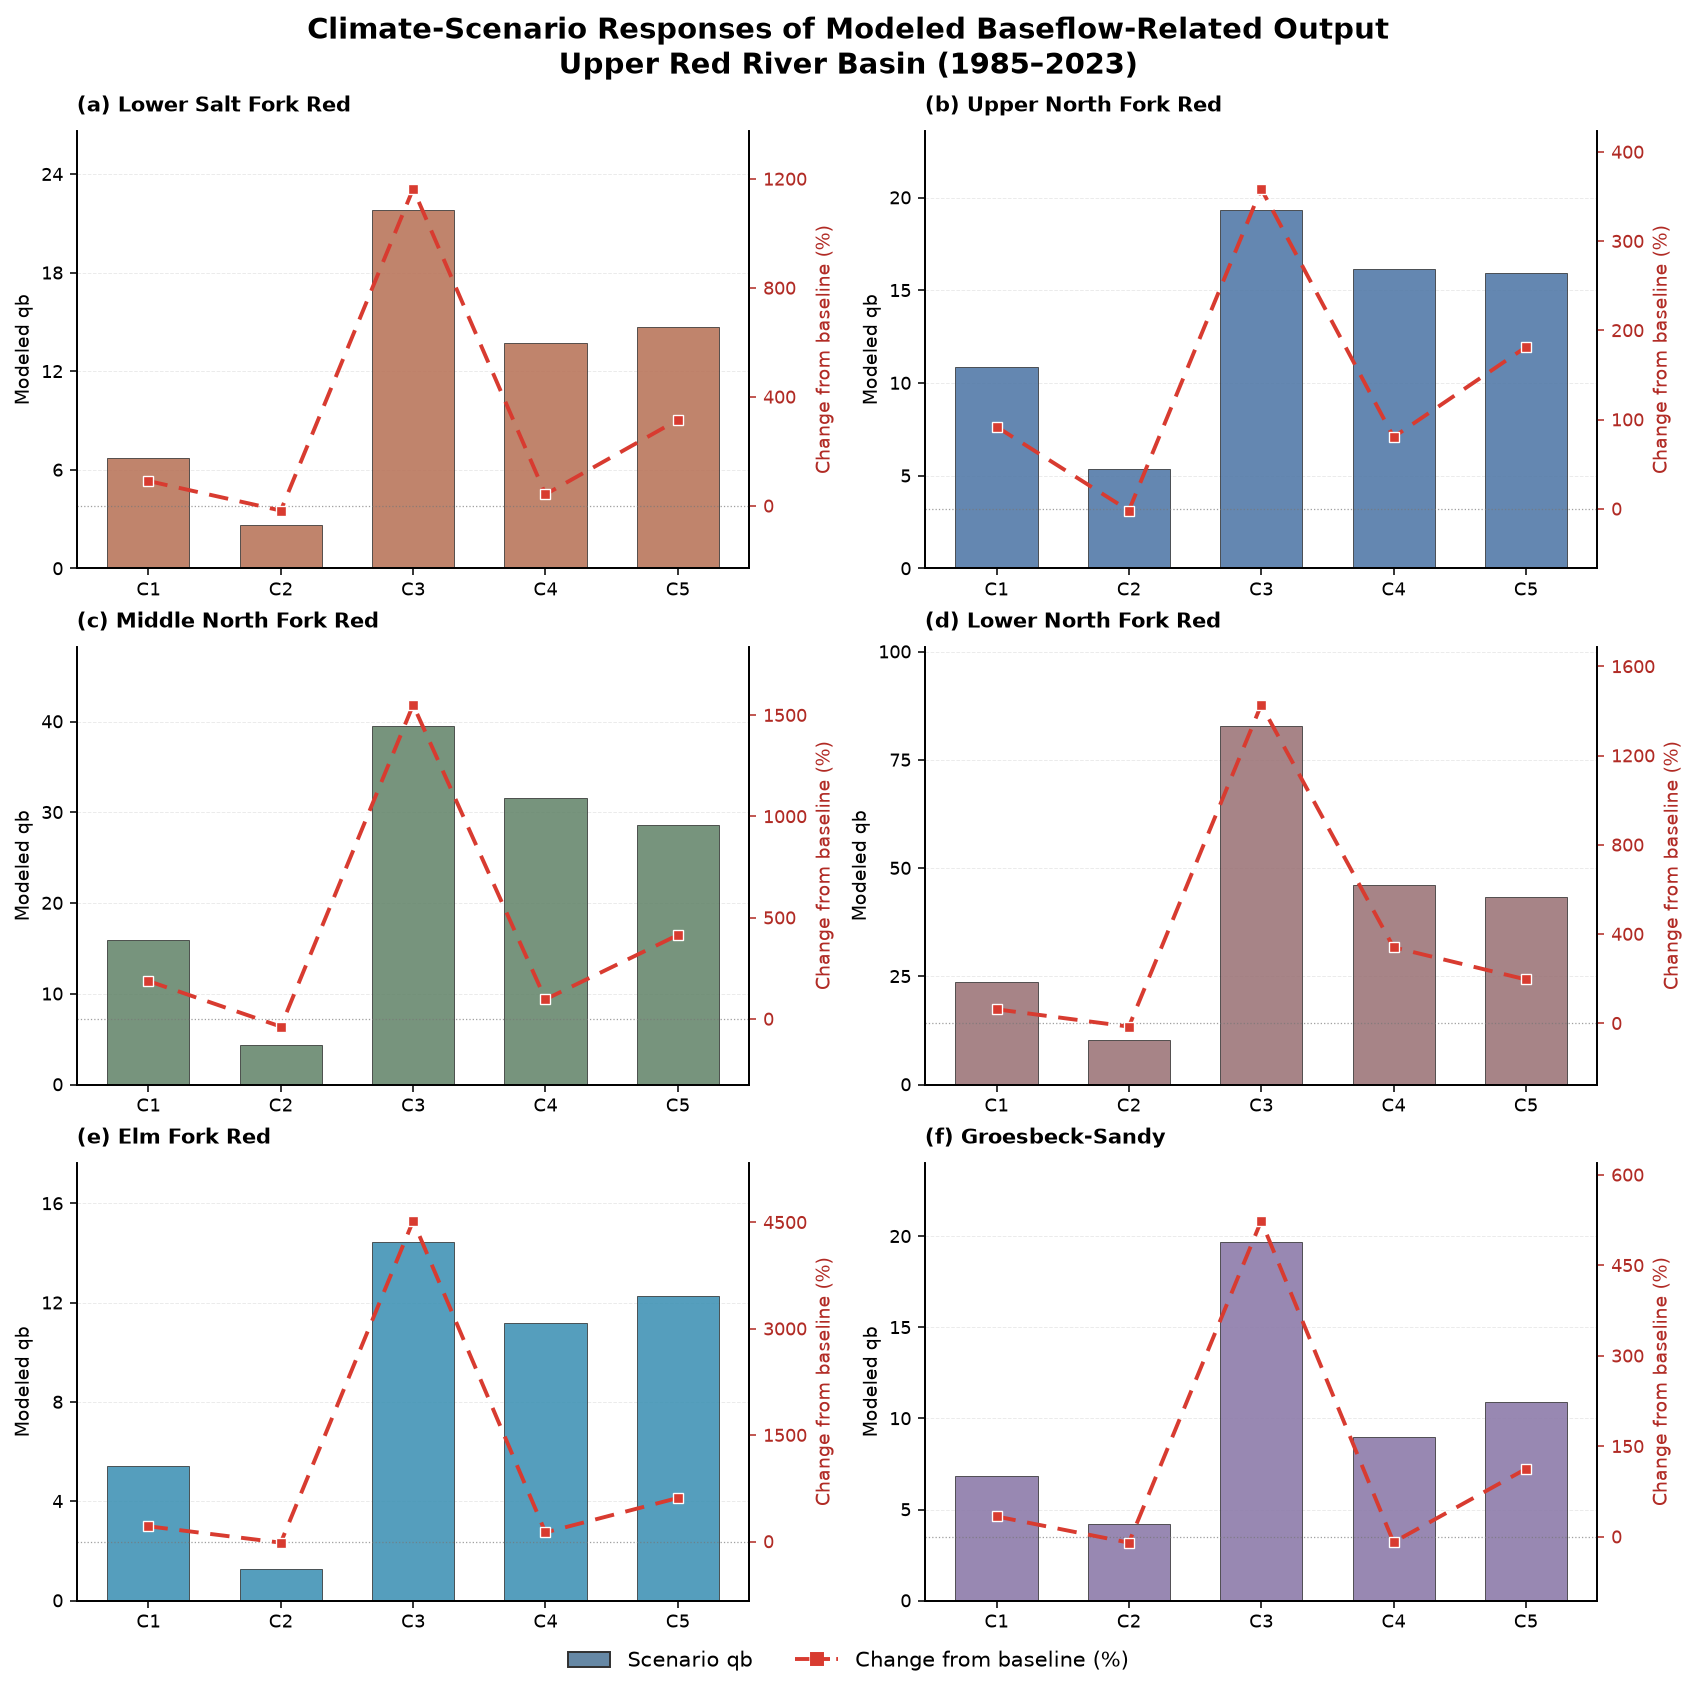

In [73]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path

# ==========================================
# 1. READ YOUR EXCEL RESULTS
# ==========================================

folder = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

excel_file = folder / "Climate_Scenario_Analysis.xlsx"

df = pd.read_excel(
    excel_file,
    sheet_name="Watershed Results",
    dtype={"HUC8": str}
)

# Required columns
required = [
    "Scenario", "HUC8", "NAME",
    "qb_scenario", "Percent_qb"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Set scenario order
scenario_order = ["C1", "C2", "C3", "C4", "C5"]

# Check that all watershed-scenario pairs exist
counts = df.groupby("HUC8")["Scenario"].nunique()

if len(counts) != 6 or not counts.eq(5).all():
    raise ValueError(
        "Expected 6 watersheds with all 5 scenarios each."
    )

# ==========================================
# 2. FIGURE STYLE
# ==========================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.9,
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# Six professional colors, one per watershed
colors = [
    "#B87358",
    "#4F77A6",
    "#64856B",
    "#9B7376",
    "#3D91B4",
    "#8A78A8"
]

watersheds = (
    df[["HUC8", "NAME"]]
    .drop_duplicates()
    .sort_values("HUC8")
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 12),
    constrained_layout=True
)

axes = axes.flatten()

# ==========================================
# 3. DRAW SIX PANELS
# ==========================================

for i, (_, watershed) in enumerate(
    watersheds.iterrows()
):

    ax = axes[i]
    huc = watershed["HUC8"]
    name = watershed["NAME"]

    sub = (
        df[df["HUC8"] == huc]
        .set_index("Scenario")
        .reindex(scenario_order)
    )

    x = np.arange(len(scenario_order))

    qb = sub["qb_scenario"].astype(float).values
    pct = sub["Percent_qb"].astype(float).values

    # Bars: scenario qb
    bars = ax.bar(
        x,
        qb,
        width=0.62,
        color=colors[i],
        edgecolor="#303030",
        linewidth=0.45,
        alpha=0.92,
        zorder=2
    )

    # Subtle top-to-bottom bar gradient
    for bar in bars:
        bar.set_alpha(0.88)

    ax.set_ylim(
        0,
        max(qb) * 1.22 if max(qb) > 0 else 1
    )

    ax.set_xticks(x)
    ax.set_xticklabels(scenario_order)

    ax.set_title(
        f"({chr(97+i)}) {name}",
        loc="left",
        fontweight="bold",
        pad=10
    )

    ax.set_ylabel("Modeled qb")

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25,
        zorder=0
    )

    # Secondary axis: percentage change
    ax2 = ax.twinx()

    ax2.plot(
        x,
        pct,
        color="#D83B30",
        linestyle=(0, (5, 3)),
        linewidth=2,
        marker="s",
        markersize=5.5,
        markerfacecolor="#D83B30",
        markeredgecolor="white",
        markeredgewidth=0.7,
        zorder=5
    )

    ax2.axhline(
        0,
        color="#777777",
        linewidth=0.65,
        linestyle=":",
        alpha=0.7
    )

    valid_pct = pct[np.isfinite(pct)]

    if len(valid_pct):
        low = min(0, valid_pct.min())
        high = max(0, valid_pct.max())
        pad = max((high-low)*0.18, 5)
        ax2.set_ylim(low-pad, high+pad)

    ax2.set_ylabel(
        "Change from baseline (%)",
        color="#B12B25"
    )

    ax2.tick_params(
        axis="y",
        colors="#B12B25"
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax2.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.spines["top"].set_visible(False)
    ax2.spines["top"].set_visible(False)

# ==========================================
# 4. LEGEND AND FIGURE CAPTION
# ==========================================

legend_items = [
    Patch(
        facecolor="#6688A5",
        edgecolor="#303030",
        label="Scenario qb"
    ),
    Line2D(
        [0], [0],
        color="#D83B30",
        linewidth=2,
        linestyle="--",
        marker="s",
        label="Change from baseline (%)"
    )
]

fig.legend(
    handles=legend_items,
    loc="outside lower center",
    ncol=2,
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "Climate-Scenario Responses of Modeled Baseflow-Related Output\n"
    "Upper Red River Basin (1985–2023)",
    fontsize=15,
    fontweight="bold"
)

# ==========================================
# 5. SAVE HIGH-RESOLUTION FIGURES
# ==========================================

png_file = folder / "Climate_Scenarios_Six_Watersheds.png"
pdf_file = folder / "Climate_Scenarios_Six_Watersheds.pdf"
svg_file = folder / "Climate_Scenarios_Six_Watersheds.svg"

fig.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_file,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_file,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



In [74]:

from pathlib import Path

root = Path(r"E:\MYLSU\1.2_Seasonal_Water_Yield")

folders = {
    "Baseline 1985": root / "1985" / "OUTPUT",
    "Baseline 1995": root / "1995" / "OUTPUT",
    "Baseline 2005": root / "2005" / "OUTPUT_GIS_2005",
    "Baseline 2015": root / "2015" / "OUTPUT_GIS",
    "Baseline 2023": root / "OUTPUT",
    "C1": root / "Climate_Scenarios" / "C1",
    "C2": root / "Climate_Scenarios" / "C2",
    "C3": root / "Climate_Scenarios" / "C3",
    "C4": root / "Climate_Scenarios" / "C4",
    "C5": root / "Climate_Scenarios" / "C5",
}

for name, folder in folders.items():
    files = [
        p for p in folder.rglob("*.tif")
        if p.stem.lower() == "qf"
        or p.stem.lower().startswith("qf_")
    ]

    print(f"\n{name}:")
    if files:
        for p in files:
            print(" ", p)
    else:
        print("  No QF raster found")



Baseline 1985:
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\QF.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\QF_new.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_1.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_10.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_11.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_12.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_2.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_3.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_4.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_5.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_6.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_7.tif
  E:\MYLSU\1.2_Seasonal_Water_Yield\1985\OUTPUT\intermediate_outputs\qf_8.tif
  E:\MYLS

In [76]:
%pip install rasterio

   ---------------------------------------- 0.0/25.7 MB ? eta -:--:--
    --------------------------------------- 0.5/25.7 MB 4.2 MB/s eta 0:00:07
   -- ------------------------------------- 1.3/25.7 MB 3.5 MB/s eta 0:00:07
   ---- ----------------------------------- 2.6/25.7 MB 4.4 MB/s eta 0:00:06
   ------ --------------------------------- 3.9/25.7 MB 4.9 MB/s eta 0:00:05
   ------- -------------------------------- 5.0/25.7 MB 5.0 MB/s eta 0:00:05
   --------- ------------------------------ 6.3/25.7 MB 5.2 MB/s eta 0:00:04
   ----------- ---------------------------- 7.3/25.7 MB 5.1 MB/s eta 0:00:04
   ------------ --------------------------- 8.1/25.7 MB 5.0 MB/s eta 0:00:04
   ------------- -------------------------- 8.9/25.7 MB 4.8 MB/s eta 0:00:04
   --------------- ------------------------ 9.7/25.7 MB 4.8 MB/s eta 0:00:04
   ---------------- ----------------------- 10.7/25.7 MB 4.8 MB/s eta 0:00:04
   ----------------- ---------------------- 11.3/25.7 MB 4.8 MB/s eta 0:00:03
   -

In [77]:
import rasterio

print("Rasterio installed successfully!")
print("Version:", rasterio.__version__)

Rasterio installed successfully!
Version: 1.4.4


In [78]:

from pathlib import Path
import geopandas as gpd
import pandas as pd
import rasterio
from rasterio.mask import mask
import numpy as np

ROOT = Path(r"E:\MYLSU\1.2_Seasonal_Water_Yield")
OUT = ROOT / "Climate_Scenarios"

WATERSHED = ROOT / "AOI" / "final_watershed_area11122.shp"

rasters = {
    "Baseline_1985": ROOT / "1985" / "OUTPUT" / "QF_new.tif",
    "Baseline_1995": ROOT / "1995" / "OUTPUT" / "QF_new.tif",
    "Baseline_2005": ROOT / "2005" / "OUTPUT_GIS_2005" / "QF_new.tif",
    "Baseline_2015": ROOT / "2015" / "OUTPUT_GIS" / "QF_new.tif",
    "Baseline_2023": ROOT / "OUTPUT" / "QF_New.tif",
    "C1": OUT / "C1" / "QF_C1.tif",
    "C2": OUT / "C2" / "QF_C2.tif",
    "C3": OUT / "C3" / "QF_C3.tif",
    "C4": OUT / "C4" / "QF_C4.tif",
    "C5": OUT / "C5" / "QF_C5.tif",
}

watersheds = gpd.read_file(WATERSHED)
watersheds["HUC8"] = watersheds["HUC8"].astype(str)

records = []

for run_name, raster_path in rasters.items():
    if not raster_path.exists():
        raise FileNotFoundError(raster_path)

    with rasterio.open(raster_path) as src:
        projected = watersheds.to_crs(src.crs)

        for _, ws in projected.iterrows():
            clipped, _ = mask(
                src,
                [ws.geometry],
                crop=True,
                filled=False
            )

            values = clipped[0].compressed()
            values = values[np.isfinite(values)]

            mean_qf = (
                float(values.mean())
                if len(values) > 0 else np.nan
            )

            records.append({
                "Run": run_name,
                "HUC8": ws["HUC8"],
                "NAME": ws["NAME"],
                "Mean_QF": mean_qf,
                "Valid_Pixels": len(values)
            })

qf_results = pd.DataFrame(records)

output_csv = OUT / "All_Quickflow_Watershed_Means.csv"
qf_results.to_csv(output_csv, index=False)

print("Quickflow extraction complete!")
print("Total records:", len(qf_results))
print("\nMean QF by run:")
print(
    qf_results.groupby("Run")["Mean_QF"]
    .mean().round(3).to_string()
)
print("\nSaved:", output_csv)


Quickflow extraction complete!
Total records: 60

Mean QF by run:
Run
Baseline_1985    152.794
Baseline_1995    171.023
Baseline_2005     44.712
Baseline_2015    100.638
Baseline_2023     53.663
C1               158.344
C2                37.980
C3                83.956
C4                43.408
C5                43.014

Saved: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\All_Quickflow_Watershed_Means.csv


In [79]:

from pathlib import Path
import pandas as pd
import numpy as np

folder = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

df = pd.read_csv(
    folder / "All_Quickflow_Watershed_Means.csv",
    dtype={"HUC8": str}
)

comparisons = {
    "C1": 1985,
    "C2": 1995,
    "C3": 2005,
    "C4": 2015,
    "C5": 1985
}

results = []

for scenario, year in comparisons.items():
    base = df[df["Run"] == f"Baseline_{year}"].copy()
    scen = df[df["Run"] == scenario].copy()

    if len(base) != 6 or len(scen) != 6:
        raise ValueError(f"{scenario}: Expected 6 watersheds")

    merged = scen.merge(
        base[["HUC8", "Mean_QF"]],
        on="HUC8",
        suffixes=("_scenario", "_baseline"),
        validate="one_to_one"
    )

    if len(merged) != 6:
        raise ValueError(f"{scenario}: Watershed mismatch")

    merged["Scenario"] = scenario
    merged["Baseline_Year"] = year

    merged["Delta_QF"] = (
        merged["Mean_QF_scenario"]
        - merged["Mean_QF_baseline"]
    )

    merged["Percent_Change_QF"] = (
        100 * merged["Delta_QF"]
        / merged["Mean_QF_baseline"].replace(0, np.nan)
    )

    results.append(merged)

details = pd.concat(results, ignore_index=True)

summary = (
    details.groupby("Scenario", as_index=False)
    .agg(
        Baseline_QF=("Mean_QF_baseline", "mean"),
        Scenario_QF=("Mean_QF_scenario", "mean"),
        Delta_QF=("Delta_QF", "mean")
    )
)

summary["Percent_Change_QF"] = (
    100 * summary["Delta_QF"] / summary["Baseline_QF"]
)

output = folder / "Quickflow_Climate_Scenario_Analysis.xlsx"

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    details.to_excel(
        writer, sheet_name="Watershed Results", index=False
    )
    summary.to_excel(
        writer, sheet_name="Scenario Summary", index=False
    )

print("SUCCESS! Quickflow Excel analysis created.")
print("\n", summary.round(3).to_string(index=False))
print("\nSaved to:", output)


SUCCESS! Quickflow Excel analysis created.

 Scenario  Baseline_QF  Scenario_QF  Delta_QF  Percent_Change_QF
      C1      152.794      158.344     5.550              3.632
      C2      171.023       37.980  -133.043            -77.792
      C3       44.712       83.956    39.245             87.773
      C4      100.638       43.408   -57.230            -56.867
      C5      152.794       43.014  -109.780            -71.848

Saved to: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_Climate_Scenario_Analysis.xlsx


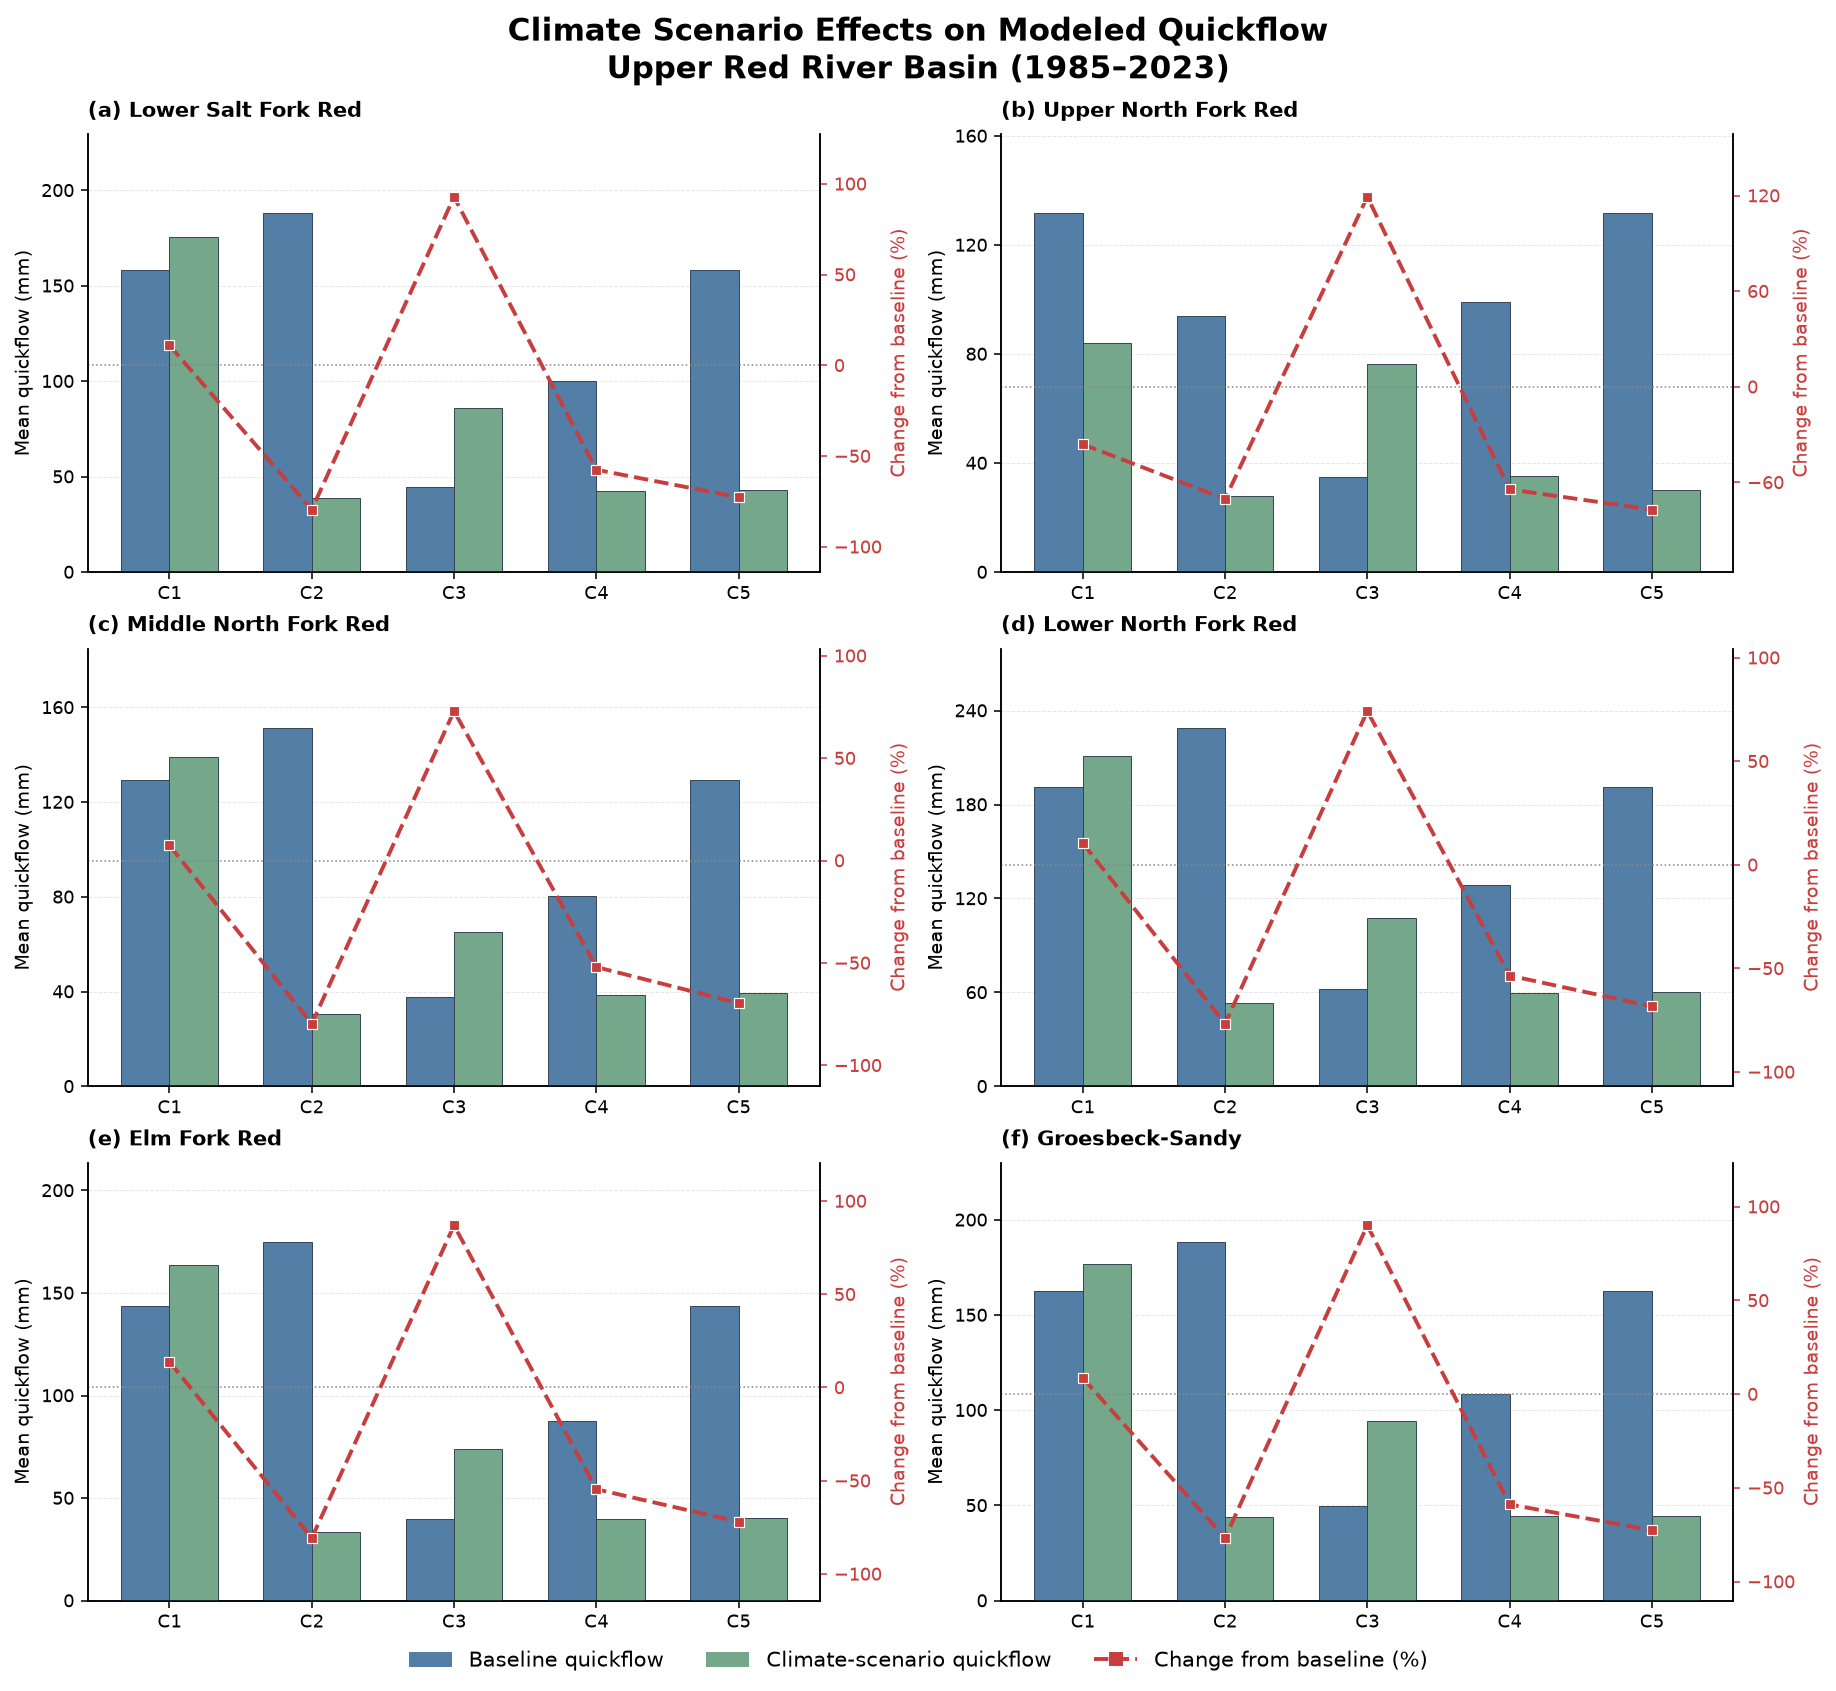

Quickflow figure generated successfully!
PNG: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_Climate_Scenarios_6_Watersheds.png
PDF: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_Climate_Scenarios_6_Watersheds.pdf
SVG: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_Climate_Scenarios_6_Watersheds.svg


In [80]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from pathlib import Path

# ==========================================
# 1. READ YOUR QUICKFLOW EXCEL FILE
# ==========================================

folder = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

excel_file = folder / "Quickflow_Climate_Scenario_Analysis.xlsx"

df = pd.read_excel(
    excel_file,
    sheet_name="Watershed Results",
    dtype={"HUC8": str}
)

required = [
    "Scenario", "HUC8", "NAME",
    "Mean_QF_baseline",
    "Mean_QF_scenario",
    "Percent_Change_QF"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

scenario_order = ["C1", "C2", "C3", "C4", "C5"]

if df.duplicated(["HUC8", "Scenario"]).any():
    raise ValueError("Duplicate watershed-scenario records found")

if len(df) != 30:
    raise ValueError(f"Expected 30 records, found {len(df)}")

# ==========================================
# 2. FIGURE STYLE
# ==========================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

baseline_color = "#537FA6"
scenario_color = "#75A88B"
line_color = "#C83D3D"

watersheds = (
    df[["HUC8", "NAME"]]
    .drop_duplicates()
    .sort_values("HUC8")
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 12),
    constrained_layout=True
)

axes = axes.flatten()

# ==========================================
# 3. CREATE THE SIX WATERSHED PANELS
# ==========================================

for i, (_, watershed) in enumerate(watersheds.iterrows()):

    ax = axes[i]

    huc = watershed["HUC8"]
    name = watershed["NAME"]

    sub = (
        df[df["HUC8"] == huc]
        .set_index("Scenario")
        .reindex(scenario_order)
    )

    if sub[required[3:]].isna().any().any():
        raise ValueError(f"Missing results for watershed {huc}")

    baseline = sub["Mean_QF_baseline"].to_numpy(float)
    scenario = sub["Mean_QF_scenario"].to_numpy(float)
    percent = sub["Percent_Change_QF"].to_numpy(float)

    x = np.arange(5)
    width = 0.34

    # Baseline QF
    ax.bar(
        x - width/2,
        baseline,
        width,
        color=baseline_color,
        edgecolor="#344454",
        linewidth=0.5,
        label="Baseline QF",
        zorder=3
    )

    # Climate-scenario QF
    ax.bar(
        x + width/2,
        scenario,
        width,
        color=scenario_color,
        edgecolor="#344454",
        linewidth=0.5,
        label="Scenario QF",
        zorder=3
    )

    ax.set_title(
        f"({chr(97+i)}) {name}",
        loc="left",
        fontweight="bold",
        pad=9
    )

    ax.set_xticks(x)
    ax.set_xticklabels(scenario_order)

    ax.set_ylabel("Mean quickflow (mm)")

    ax.set_ylim(
        0,
        max(np.max(baseline), np.max(scenario)) * 1.22
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.3,
        zorder=0
    )

    ax.spines["top"].set_visible(False)

    # Percentage change on secondary axis
    ax2 = ax.twinx()

    ax2.plot(
        x,
        percent,
        color=line_color,
        linewidth=2,
        linestyle="--",
        marker="s",
        markersize=5,
        markerfacecolor=line_color,
        markeredgecolor="white",
        markeredgewidth=0.6,
        zorder=5
    )

    ax2.axhline(
        0,
        color="#888888",
        linestyle=":",
        linewidth=0.8
    )

    lower = min(0, np.min(percent))
    upper = max(0, np.max(percent))
    padding = max((upper - lower) * 0.2, 5)

    ax2.set_ylim(lower-padding, upper+padding)

    ax2.set_ylabel(
        "Change from baseline (%)",
        color=line_color
    )

    ax2.tick_params(axis="y", colors=line_color)

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax2.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax2.spines["top"].set_visible(False)

# ==========================================
# 4. FIGURE LEGEND
# ==========================================

legend_items = [
    Patch(
        facecolor=baseline_color,
        label="Baseline quickflow"
    ),
    Patch(
        facecolor=scenario_color,
        label="Climate-scenario quickflow"
    ),
    Line2D(
        [0], [0],
        color=line_color,
        linestyle="--",
        marker="s",
        linewidth=2,
        label="Change from baseline (%)"
    )
]

fig.legend(
    handles=legend_items,
    loc="outside lower center",
    ncol=3,
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "Climate Scenario Effects on Modeled Quickflow\n"
    "Upper Red River Basin (1985–2023)",
    fontsize=16,
    fontweight="bold"
)

# ==========================================
# 5. SAVE FIGURE
# ==========================================

png_file = folder / "Quickflow_Climate_Scenarios_6_Watersheds.png"
pdf_file = folder / "Quickflow_Climate_Scenarios_6_Watersheds.pdf"
svg_file = folder / "Quickflow_Climate_Scenarios_6_Watersheds.svg"

fig.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_file,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_file,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Quickflow figure generated successfully!")
print("PNG:", png_file)
print("PDF:", pdf_file)
print("SVG:", svg_file)


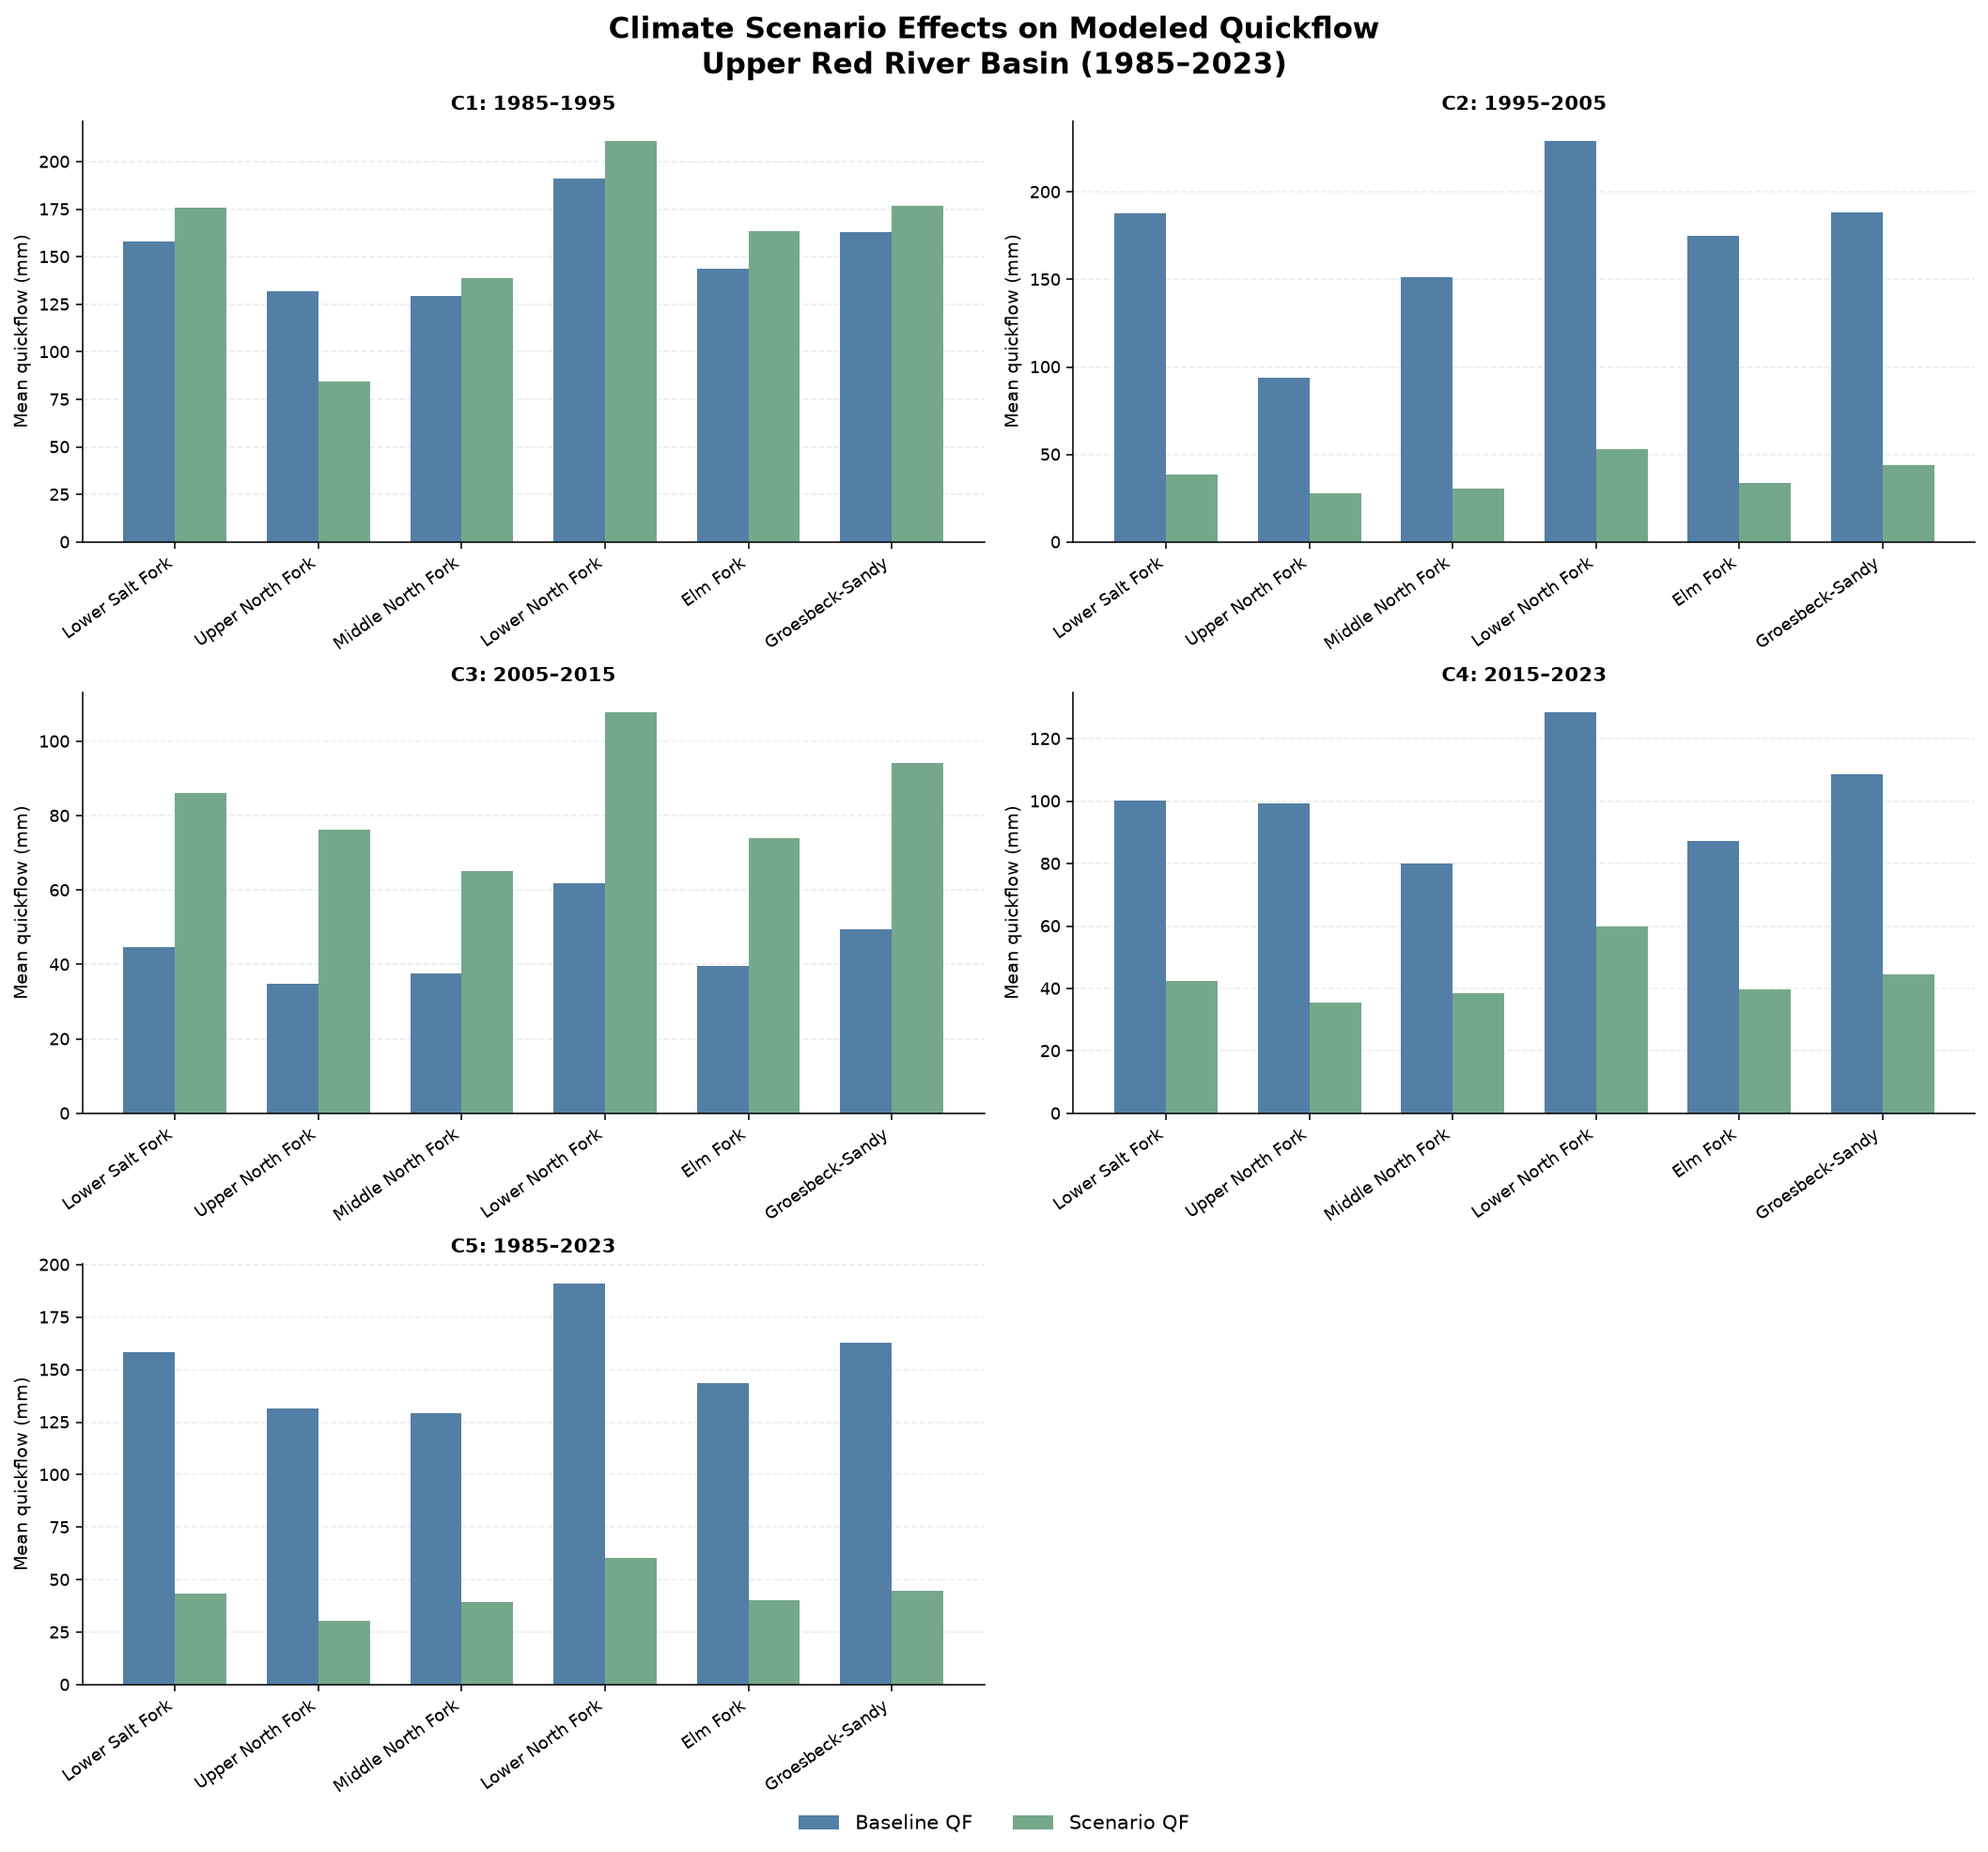

Saved: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_C1.png
Saved: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_C2.png
Saved: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_C3.png
Saved: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_C4.png
Saved: E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios\Quickflow_C5.png

All five scenario figures generated successfully!


In [81]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

folder = Path(
    r"E:\MYLSU\1.2_Seasonal_Water_Yield\Climate_Scenarios"
)

df = pd.read_excel(
    folder / "Quickflow_Climate_Scenario_Analysis.xlsx",
    sheet_name="Watershed Results",
    dtype={"HUC8": str}
)

scenarios = {
    "C1": "1985–1995",
    "C2": "1995–2005",
    "C3": "2005–2015",
    "C4": "2015–2023",
    "C5": "1985–2023"
}

watersheds = (
    df[["HUC8", "NAME"]]
    .drop_duplicates()
    .sort_values("HUC8")
)

order = watersheds["HUC8"].tolist()
names = watersheds["NAME"].tolist()

# Short labels for readability
short_names = [
    "Lower Salt Fork",
    "Upper North Fork",
    "Middle North Fork",
    "Lower North Fork",
    "Elm Fork",
    "Groesbeck-Sandy"
]

colors = {
    "baseline": "#537FA6",
    "scenario": "#75A88B"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "pdf.fonttype": 42
})

def draw_scenario(ax, scenario, period):

    sub = (
        df[df["Scenario"] == scenario]
        .set_index("HUC8")
        .reindex(order)
    )

    if sub[
        ["Mean_QF_baseline", "Mean_QF_scenario"]
    ].isna().any().any():
        raise ValueError(f"Missing values for {scenario}")

    x = np.arange(len(order))
    width = 0.36

    ax.bar(
        x - width/2,
        sub["Mean_QF_baseline"],
        width,
        color=colors["baseline"],
        label="Baseline QF"
    )

    ax.bar(
        x + width/2,
        sub["Mean_QF_scenario"],
        width,
        color=colors["scenario"],
        label="Scenario QF"
    )

    ax.set_title(
        f"{scenario}: {period}",
        fontweight="bold"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        short_names,
        rotation=35,
        ha="right"
    )

    ax.set_ylabel("Mean quickflow (mm)")
    ax.set_ylim(bottom=0)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ==========================================
# COMBINED FIVE-PANEL FIGURE
# ==========================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 14),
    constrained_layout=True
)

axes = axes.flatten()

for i, (scenario, period) in enumerate(scenarios.items()):
    draw_scenario(axes[i], scenario, period)

axes[5].axis("off")

legend = [
    Patch(facecolor=colors["baseline"], label="Baseline QF"),
    Patch(facecolor=colors["scenario"], label="Scenario QF")
]

fig.legend(
    handles=legend,
    loc="outside lower center",
    ncol=2,
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "Climate Scenario Effects on Modeled Quickflow\n"
    "Upper Red River Basin (1985–2023)",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    folder / "Quickflow_Five_Scenario_Panels.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    folder / "Quickflow_Five_Scenario_Panels.pdf",
    bbox_inches="tight"
)

plt.show()

# ==========================================
# FIVE INDIVIDUAL FIGURES
# ==========================================

for scenario, period in scenarios.items():

    fig, ax = plt.subplots(figsize=(10, 5.5))

    draw_scenario(ax, scenario, period)

    ax.legend(frameon=False)

    fig.tight_layout()

    output = folder / f"Quickflow_{scenario}.png"

    fig.savefig(
        output,
        dpi=600,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Saved:", output)

print("\nAll five scenario figures generated successfully!")
